# DS201 · Lab 3 — Bài tập về nhà: LSTM, GRU và BiLSTM

**Sinh viên:** Đặng Nguyên Thọ · **MSSV:** 24521715

Cấu hình chung theo đề: 5 lớp, hidden 256 (mỗi chiều với BiLSTM), embedding 300 học từ đầu, dropout 0.3, Adam lr=1e-3, batch 32, clip_grad_norm 1.0, seed 42, tối đa 10 epoch, giữ checkpoint có F1 dev cao nhất; test chấm một lần.

**Hướng cài đặt:** sampler gom batch theo độ dài; một encoder dùng chung cho cả 3 bài; đầu phân loại ghép h_n lớp cuối với max-pooling; loss có trọng số lớp (neutral chỉ chiếm khoảng 4% tập train); phân tích lỗi NER tự động.

## 0. Môi trường và cấu hình

In [ ]:
# %pip install -q torch numpy pandas matplotlib scikit-learn seqeval
import hashlib, json, random, time, urllib.request
from collections import Counter
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset, Sampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support)
from seqeval.metrics import classification_report as seq_report
from seqeval.metrics import f1_score as seq_f1, precision_score as seq_p, recall_score as seq_r
from seqeval.metrics.sequence_labeling import get_entities
from seqeval.scheme import IOB2


@dataclass(frozen=True)
class Config:
    emb_dim: int = 300
    hidden: int = 256
    layers: int = 5
    dropout: float = 0.3
    batch_size: int = 32
    lr: float = 1e-3
    clip: float = 1.0
    epochs: int = 10
    seed: int = 42
    min_freq: int = 2


CFG = Config()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd()
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)
IGNORE = -100


def set_seed(seed: int = CFG.seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


set_seed()
print(f"torch {torch.__version__} | device={DEVICE} | threads={torch.get_num_threads()}")
print(asdict(CFG))

torch 2.15.0+cu132 | device=cpu | threads=2
{'emb_dim': 300, 'hidden': 256, 'layers': 5, 'dropout': 0.3, 'batch_size': 32, 'lr': 0.001, 'clip': 1.0, 'epochs': 10, 'seed': 42, 'min_freq': 2}


## 1. Dữ liệu

Tải từ nguồn gốc (UIT-VSFC trên Google Drive của đề, PhoNER từ kho VinAI) và xác thực bằng SHA-256. Nếu tệp đã có sẵn trong `data/` thì chỉ kiểm tra checksum. Dữ liệu không được đính kèm khi nộp.

In [ ]:
SOURCES = {
    "uit-vsfc/UIT-VSFC-train.json": ("https://drive.google.com/uc?export=download&id=1eJdEStCQBf3GtbOIQfIR2iS-Wb3nlfJX",
                                     "e41e65672f2ade65ee8d2d394659a2bfeabbce987f0d2ad9e19998068a78fc1e"),
    "uit-vsfc/UIT-VSFC-dev.json":   ("https://drive.google.com/uc?export=download&id=1UWbzHFeUPu4AuofOEy0Fo0SFotVZHzUe",
                                     "ab781a38209c17e640e077f83d82ecb9ea4f3469e63fc6ec2a232b0da6fbe823"),
    "uit-vsfc/UIT-VSFC-test.json":  ("https://drive.google.com/uc?export=download&id=1g4imdabNbswIu91K6zKFGalkjDBBqaQq",
                                     "14a6c5697907084086551a17c76e908dad88f2dc3b8be720c9880c8fc1212aa6"),
}
PHONER_URL = "https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/{}_syllable.json"
PHONER_SHA = {"train": "fb4097f6ac956a03e484319898db0dafc7283c135cd7888f803ad26a5a253419",
              "dev":   "c74393fb5d1547d51ddda175830892ca62a7efa2d93291b21a35cb21bfee612e",
              "test":  "4b677028d6db5e1dab74d727d88b719454da60cfeaba681d9ee401fc83b04c77"}
SOURCES.update({f"phoner/{s}_syllable.json": (PHONER_URL.format(s), h) for s, h in PHONER_SHA.items()})


def fetch_verified(rel_path, url, sha256):
    path = DATA_DIR / rel_path
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=90) as resp:
            path.write_bytes(resp.read())
    if hashlib.sha256(path.read_bytes()).hexdigest() != sha256:
        raise ValueError(f"Checksum không khớp (có thể nguồn trả về HTML): {rel_path}")
    return path


for rel, (url, sha) in SOURCES.items():
    fetch_verified(rel, url, sha)
print(f"{len(SOURCES)}/6 tệp hợp lệ (SHA-256).")

6/6 tệp hợp lệ (SHA-256).


In [ ]:
SPLITS = ("train", "dev", "test")
SENTIMENTS = ["negative", "neutral", "positive"]
SENT2ID = {s: i for i, s in enumerate(SENTIMENTS)}

vsfc = {s: json.loads((DATA_DIR / f"uit-vsfc/UIT-VSFC-{s}.json").read_text(encoding="utf-8-sig")) for s in SPLITS}
phoner = {}
for s in SPLITS:
    with open(DATA_DIR / f"phoner/{s}_syllable.json", encoding="utf-8-sig") as f:
        phoner[s] = [json.loads(line) for line in f if line.strip()]  # JSON Lines

assert [len(vsfc[s]) for s in SPLITS] == [11426, 1583, 3166]
assert [len(phoner[s]) for s in SPLITS] == [5027, 2000, 3000]
assert all(len(r["words"]) == len(r["tags"]) > 0 for s in SPLITS for r in phoner[s])

overview = pd.DataFrame({
    s: {**Counter(r["sentiment"] for r in vsfc[s]),
        "vsfc_avg_len": np.mean([len(r["sentence"].split()) for r in vsfc[s]]),
        "phoner_sents": len(phoner[s]),
        "phoner_avg_len": np.mean([len(r["words"]) for r in phoner[s]])}
    for s in SPLITS}).T[SENTIMENTS + ["vsfc_avg_len", "phoner_sents", "phoner_avg_len"]]
overview.round(1)

,negative,neutral,positive,vsfc_avg_len,phoner_sents,phoner_avg_len
train,5325.0,458.0,5643.0,14.3,5027.0,33.3
dev,705.0,73.0,805.0,13.7,2000.0,35.7
test,1409.0,167.0,1590.0,14.2,3000.0,36.1


## 2. Thành phần dùng chung

`Vocab` chỉ xây từ train (min_freq=2, `<pad>`=0, `<unk>`=1). `LengthBucketSampler` gom các câu dài gần bằng nhau vào cùng batch để giảm padding. Dataset trả kèm chỉ số gốc để sắp dự đoán về đúng thứ tự.

In [ ]:
class Vocab:
    PAD_ID, UNK_ID = 0, 1

    def __init__(self, sequences, min_freq=CFG.min_freq):
        freq = Counter(tok for seq in sequences for tok in seq)
        kept = sorted((t for t, c in freq.items() if c >= min_freq), key=lambda t: (-freq[t], t))
        self.itos = ["<pad>", "<unk>"] + kept
        self.stoi = {t: i for i, t in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(t, self.UNK_ID) for t in tokens] or [self.UNK_ID]


class IndexedDataset(Dataset):
    def __init__(self, inputs, targets):
        assert len(inputs) == len(targets)
        self.inputs, self.targets = inputs, targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, i):
        return i, self.inputs[i], self.targets[i]


class LengthBucketSampler(Sampler):
    def __init__(self, lengths, batch_size, shuffle, seed=CFG.seed, pool_batches=50):
        self.lengths = np.asarray(lengths)
        self.bs, self.shuffle = batch_size, shuffle
        self.pool = batch_size * pool_batches
        self.rng = np.random.default_rng(seed)

    def _batches(self):
        order = self.rng.permutation(len(self.lengths)) if self.shuffle else np.arange(len(self.lengths))
        batches = []
        for start in range(0, len(order), self.pool):
            chunk = order[start:start + self.pool]
            chunk = chunk[np.argsort(self.lengths[chunk], kind="stable")]
            batches += [chunk[i:i + self.bs].tolist() for i in range(0, len(chunk), self.bs)]
        if self.shuffle:
            batches = [batches[i] for i in self.rng.permutation(len(batches))]
        return batches

    def __iter__(self):
        return iter(self._batches())

    def __len__(self):
        return sum(-(-min(self.pool, len(self.lengths) - s) // self.bs)
                   for s in range(0, len(self.lengths), self.pool))


def collate(batch, seq_targets):
    idx, xs, ys = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs])
    ids = torch.full((len(xs), int(lengths.max())), Vocab.PAD_ID, dtype=torch.long)
    for row, x in enumerate(xs):
        ids[row, :len(x)] = torch.tensor(x)
    if seq_targets:
        y = torch.full_like(ids, IGNORE)
        for row, t in enumerate(ys):
            y[row, :len(t)] = torch.tensor(t)
    else:
        y = torch.tensor(ys)
    return torch.tensor(idx), ids, lengths, y


def make_loader(dataset, shuffle, seq_targets=False):
    sampler = LengthBucketSampler([len(x) for x in dataset.inputs], CFG.batch_size, shuffle)
    return DataLoader(dataset, batch_sampler=sampler,
                      collate_fn=lambda b: collate(b, seq_targets))

### Encoder và vòng huấn luyện chung

Packing giúp RNN bỏ qua các vị trí đệm. Mỗi batch: zero_grad → forward → loss → backward → clip(1.0) → step. Sau mỗi epoch đánh giá trên dev và lưu checkpoint khi F1 dev tăng.

In [ ]:
class RecurrentEncoder(nn.Module):
    CELLS = {"lstm": nn.LSTM, "gru": nn.GRU}

    def __init__(self, vocab_size, cell="lstm", bidirectional=False, cfg=CFG):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, cfg.emb_dim, padding_idx=Vocab.PAD_ID)
        self.emb_dropout = nn.Dropout(cfg.dropout)
        self.rnn = self.CELLS[cell](cfg.emb_dim, cfg.hidden, num_layers=cfg.layers, batch_first=True,
                                    dropout=cfg.dropout, bidirectional=bidirectional)
        self.out_dim = cfg.hidden * (2 if bidirectional else 1)

    def forward(self, ids, lengths):
        x = self.emb_dropout(self.embedding(ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=ids.size(1))
        h_n = state[0] if isinstance(state, tuple) else state  # LSTM: (h_n, c_n); GRU: h_n
        mask = torch.arange(ids.size(1), device=ids.device)[None, :] < lengths.to(ids.device)[:, None]
        return out, h_n, mask


def train_with_selection(model, name, train_loader, dev_loader, loss_fn, dev_score_fn, cfg=CFG):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    ckpt = OUT_DIR / f"{name}.pt"
    history, best = [], {"dev_f1": -1.0, "epoch": 0}
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        t0, loss_sum, n_items = time.perf_counter(), 0.0, 0
        for _, ids, lengths, y in train_loader:
            ids, y = ids.to(DEVICE), y.to(DEVICE)
            loss = loss_fn(model(ids, lengths), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg.clip)
            optimizer.step()
            k = int((y != IGNORE).sum())
            loss_sum, n_items = loss_sum + loss.item() * k, n_items + k
        seconds = time.perf_counter() - t0
        dev_f1 = dev_score_fn(model, dev_loader)
        history.append(dict(epoch=epoch, train_loss=loss_sum / n_items, dev_f1=dev_f1, sec=seconds))
        improved = dev_f1 > best["dev_f1"]
        if improved:
            best = {"dev_f1": dev_f1, "epoch": epoch}
            torch.save(model.state_dict(), ckpt)
        print(f"[{name}] epoch {epoch:2d} | train_loss {loss_sum / n_items:.4f} | "
              f"dev_F1 {dev_f1:.4f} | {seconds:5.1f}s{'  ← best' if improved else ''}")
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    model.eval()
    return pd.DataFrame(history), best


def plot_curves(histories, metric_name, path):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    for name, h in histories.items():
        ax[0].plot(h.epoch, h.train_loss, marker="o", label=name)
        ax[1].plot(h.epoch, h.dev_f1, marker="o", label=name)
    for a, title in zip(ax, ["Train loss", f"Dev {metric_name}"]):
        a.set(title=title, xlabel="epoch")
        a.grid(alpha=.3)
        a.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

## 3. Phân loại cảm xúc UIT-VSFC (dùng chung cho Bài 1 và 2)

Đầu vào chỉ gồm `sentence` (lowercase, tách theo khoảng trắng; dữ liệu đã có khoảng trắng quanh dấu câu), nhãn là `sentiment`. `topic` không được sử dụng.

In [ ]:
tokenize = lambda text: text.lower().split()
cls_tokens = {s: [tokenize(r["sentence"]) for r in vsfc[s]] for s in SPLITS}
cls_labels = {s: np.array([SENT2ID[r["sentiment"]] for r in vsfc[s]]) for s in SPLITS}

cls_vocab = Vocab(cls_tokens["train"])
cls_data = {s: IndexedDataset([cls_vocab.encode(t) for t in cls_tokens[s]], cls_labels[s].tolist()) for s in SPLITS}
cls_train_loader = make_loader(cls_data["train"], shuffle=True)
cls_eval_loader = {s: make_loader(cls_data[s], shuffle=False) for s in ("dev", "test")}

oov = np.mean([t not in cls_vocab.stoi for s in cls_tokens["dev"] for t in s])
print(f"Kích thước vocab: {len(cls_vocab)} | tỉ lệ token OOV trên dev: {oov:.2%}")

counts = np.bincount(cls_labels["train"], minlength=3)
class_weight = torch.tensor(np.sqrt(counts.sum() / (3 * counts)), dtype=torch.float, device=DEVICE)
print("Số mẫu train theo lớp:", dict(zip(SENTIMENTS, counts.tolist())))
print("Trọng số loss:", dict(zip(SENTIMENTS, class_weight.cpu().numpy().round(3).tolist())))

Kích thước vocab: 1535 | tỉ lệ token OOV trên dev: 0.78%


Số mẫu train theo lớp: {'negative': 5325, 'neutral': 458, 'positive': 5643}
Trọng số loss: {'negative': 0.8460000157356262, 'neutral': 2.884000062942505, 'positive': 0.8220000267028809}


In [ ]:
class SentimentRNN(nn.Module):
    """RNN 5 lớp → [h_n lớp cuối ; max-pool có mask trên output] → Linear(2H, 3). Trả về logits."""

    def __init__(self, vocab_size, cell, n_classes=3, cfg=CFG):
        super().__init__()
        self.encoder = RecurrentEncoder(vocab_size, cell, bidirectional=False, cfg=cfg)
        self.head = nn.Sequential(nn.Dropout(cfg.dropout), nn.Linear(2 * self.encoder.out_dim, n_classes))

    def forward(self, ids, lengths):
        out, h_n, mask = self.encoder(ids, lengths)
        pooled = out.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(dim=1).values
        return self.head(torch.cat([h_n[-1], pooled], dim=-1))


@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    idx, probs = [], []
    for i, ids, lengths, _ in loader:
        probs.append(model(ids.to(DEVICE), lengths).softmax(-1).cpu())
        idx.append(i)
    return torch.cat(probs)[torch.cat(idx).argsort()].numpy()


def macro_f1_on(split):
    return lambda model, loader: f1_score(cls_labels[split], predict_proba(model, loader).argmax(1), average="macro")


def cls_summary(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2], zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision_macro": p, "recall_macro": r, "f1_macro": f,
            **{f"F1_{c}": v for c, v in zip(SENTIMENTS, per_class)}}


cls_loss = nn.CrossEntropyLoss(weight=class_weight)
results = {}

### Baseline TF-IDF + Logistic Regression

Dùng cùng train/dev/test và cùng cách tách token với RNN; `class_weight="balanced"` để đặt cùng tiêu chí với loss có trọng số. Vectorizer và mô hình chỉ fit trên train.

In [ ]:
t0 = time.perf_counter()
tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=True,
                        ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(r["sentence"] for r in vsfc["train"])
logreg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=CFG.seed)
logreg.fit(X_train, cls_labels["train"])
tfidf_fit_sec = time.perf_counter() - t0

tfidf_pred = {s: logreg.predict(tfidf.transform(r["sentence"] for r in vsfc[s])) for s in ("dev", "test")}
results["TF-IDF + LogReg"] = dict(dev_f1=f1_score(cls_labels["dev"], tfidf_pred["dev"], average="macro"),
                                  test=cls_summary(cls_labels["test"], tfidf_pred["test"]),
                                  params=X_train.shape[1] * 3 + 3, sec_per_epoch=tfidf_fit_sec, best_epoch="-")
print(f"Fit {tfidf_fit_sec:.1f}s | {X_train.shape[1]} đặc trưng | dev macro-F1 = {results['TF-IDF + LogReg']['dev_f1']:.4f}")

Fit 0.6s | 13895 đặc trưng | dev macro-F1 = 0.7781


## Bài 1 — LSTM 5 lớp, hidden 256

In [ ]:
def run_sentiment(cell, name):
    set_seed()
    model = SentimentRNN(len(cls_vocab), cell).to(DEVICE)
    print(model.encoder.rnn, f"\nSố tham số: {n_params(model):,}")
    hist, best = train_with_selection(model, name, cls_train_loader, cls_eval_loader["dev"],
                                      cls_loss, macro_f1_on("dev"))
    test_pred = predict_proba(model, cls_eval_loader["test"]).argmax(1)
    results[name] = dict(dev_f1=best["dev_f1"], test=cls_summary(cls_labels["test"], test_pred),
                         params=n_params(model), sec_per_epoch=hist.sec.mean(), best_epoch=best["epoch"])
    print(f"\nCheckpoint chọn: epoch {best['epoch']} (dev macro-F1 {best['dev_f1']:.4f})")
    print(f"TEST — {name}\n" + classification_report(cls_labels["test"], test_pred,
                                                     target_names=SENTIMENTS, digits=4))
    return model, hist, test_pred


lstm, lstm_hist, lstm_test_pred = run_sentiment("lstm", "LSTM-5L")

LSTM(300, 256, num_layers=5, batch_first=True, dropout=0.3) 
Số tham số: 3,138,775


[LSTM-5L] epoch  1 | train_loss 0.6063 | dev_F1 0.7229 |  43.1s  ← best


[LSTM-5L] epoch  2 | train_loss 0.4104 | dev_F1 0.7678 |  39.3s  ← best


[LSTM-5L] epoch  3 | train_loss 0.3467 | dev_F1 0.7944 |  40.0s  ← best


[LSTM-5L] epoch  4 | train_loss 0.3068 | dev_F1 0.7958 |  39.1s  ← best


[LSTM-5L] epoch  5 | train_loss 0.2697 | dev_F1 0.7973 |  39.7s  ← best


... (2 outputs left out)

[LSTM-5L] epoch  8 | train_loss 0.1813 | dev_F1 0.7876 |  41.9s


[LSTM-5L] epoch  9 | train_loss 0.1635 | dev_F1 0.8086 |  41.4s  ← best


[LSTM-5L] epoch 10 | train_loss 0.1397 | dev_F1 0.7925 |  41.9s



Checkpoint chọn: epoch 9 (dev macro-F1 0.8086)
TEST — LSTM-5L
              precision    recall  f1-score   support

    negative     0.8982    0.9326    0.9150      1409
     neutral     0.5888    0.3772    0.4599       167
    positive     0.9254    0.9289    0.9272      1590

    accuracy                         0.9015      3166
   macro avg     0.8041    0.7463    0.7674      3166
weighted avg     0.8955    0.9015    0.8971      3166



In [ ]:
def show_test_table(names):
    return pd.DataFrame({n: results[n]["test"] for n in names}).T.round(4)


show_test_table(["TF-IDF + LogReg", "LSTM-5L"])

,accuracy,precision_macro,recall_macro,f1_macro,F1_negative,F1_neutral,F1_positive
TF-IDF + LogReg,0.8730,0.7228,0.7519,0.7335,0.8956,0.3909,0.9140
LSTM-5L,0.9015,0.8041,0.7463,0.7674,0.9150,0.4599,0.9272


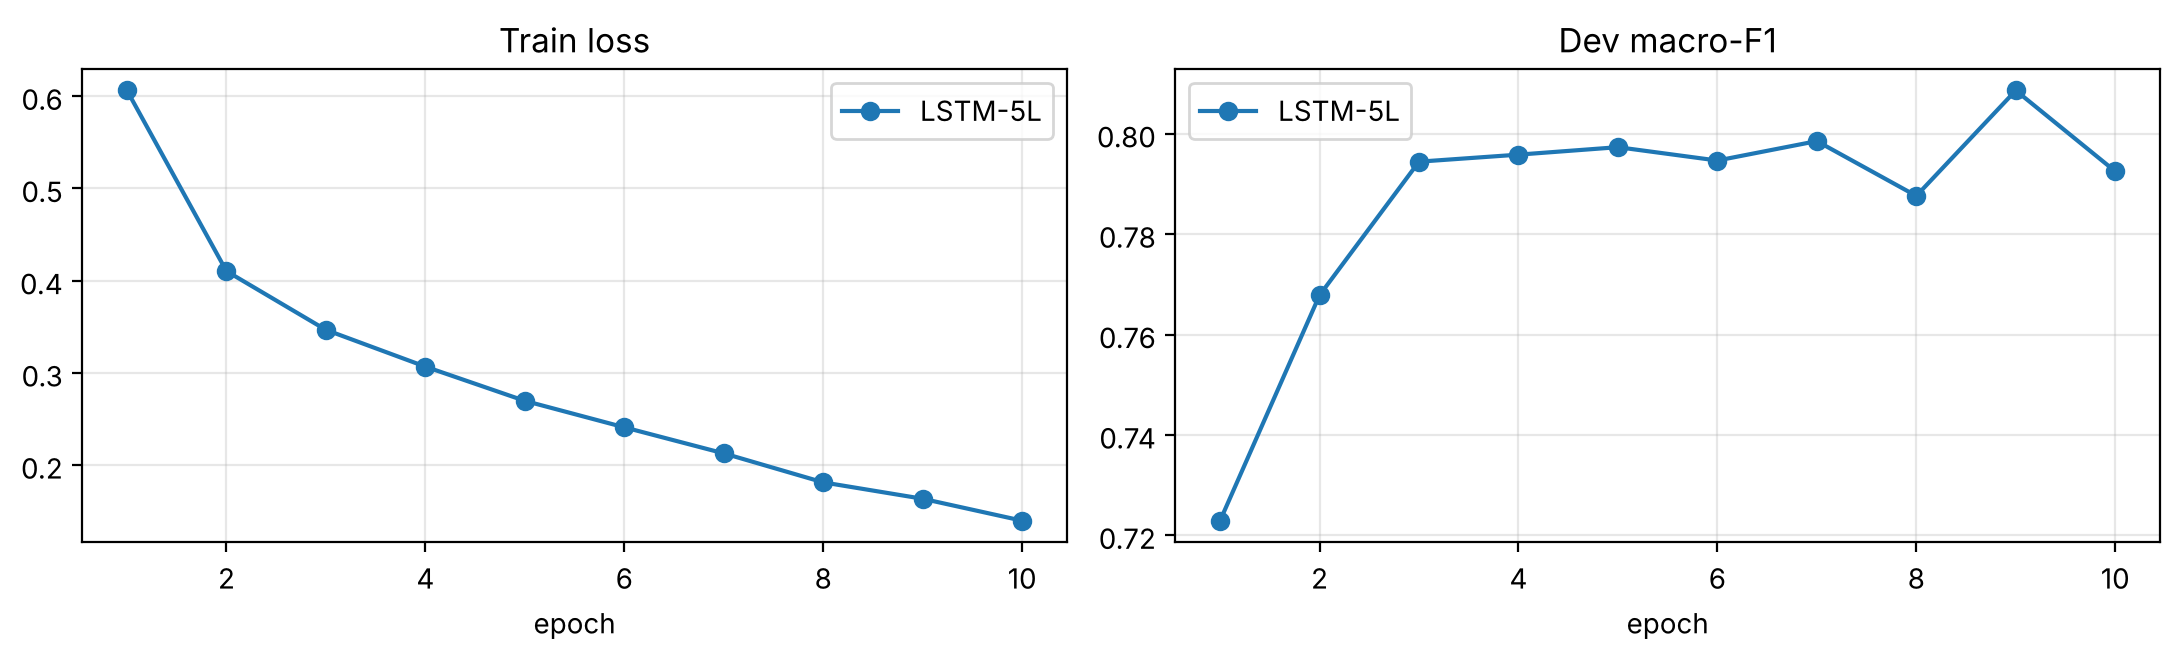

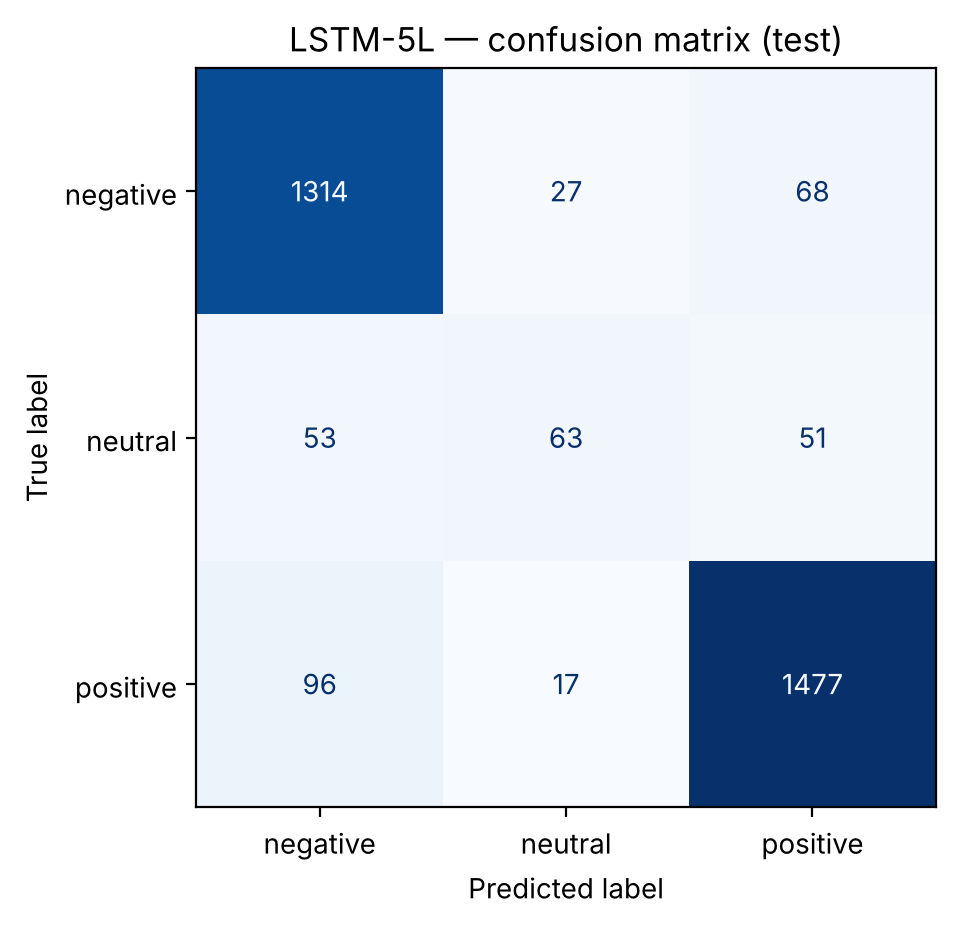

Tham số: 3,138,775 | Thời gian TB/epoch: 42.8s


In [ ]:
plot_curves({"LSTM-5L": lstm_hist}, "macro-F1", OUT_DIR / "lstm_curves.png")
ConfusionMatrixDisplay.from_predictions(cls_labels["test"], lstm_test_pred, display_labels=SENTIMENTS,
                                        cmap="Blues", colorbar=False)
plt.title("LSTM-5L — confusion matrix (test)")
plt.show()
print(f"Tham số: {results['LSTM-5L']['params']:,} | Thời gian TB/epoch: {results['LSTM-5L']['sec_per_epoch']:.1f}s")

### Phân tích lỗi trên dev (LSTM)

In [ ]:
def error_table(model, split="dev"):
    proba = predict_proba(model, cls_eval_loader[split])
    pred, gold = proba.argmax(1), cls_labels[split]
    df = pd.DataFrame({"sentence": [r["sentence"] for r in vsfc[split]],
                       "gold": np.array(SENTIMENTS)[gold], "pred": np.array(SENTIMENTS)[pred],
                       "conf": proba.max(1).round(3)})
    return df[pred != gold]


lstm_err = error_table(lstm)
print(f"Số câu sai trên dev: {len(lstm_err)}/{len(vsfc['dev'])}")
display(lstm_err.groupby(["gold", "pred"]).size().rename("count").sort_values(ascending=False).to_frame())
with pd.option_context("display.max_colwidth", 140):
    display(lstm_err.sort_values("conf", ascending=False).groupby(["gold", "pred"]).head(3))

Số câu sai trên dev: 123/1583


count
gold     pred           
positive negative     36
negative positive     28
neutral  positive     20
         negative     17
negative neutral      13
positive neutral       9

,sentence,gold,pred,conf
732,thầy hướng dẫn thực hành rất không tốt .,negative,positive,0.998
1582,thầy vừa dạy vừa chat hoặc gọi điện thoại thường xuyên .,negative,positive,0.998
939,"cô dạy rất nhiệt tình , tận tâm và chu đáo .",negative,positive,0.998
1060,điều này tạo cho sinh viên sự chủ động trong học tập .,neutral,positive,0.997
117,sự nhiệt tình .,neutral,positive,0.997
127,cẩn thận .,neutral,positive,0.996
855,nhanh .,neutral,negative,0.995
941,nói chung again 10 fraction 10 .,positive,neutral,0.995
1426,do là hình thức thực hành 2 .,negative,neutral,0.995
1183,"cô điểm danh mình em lúc đầu giờ , cuối giờ mới điểm danh mấy bạn kia colonsadcolon .",negative,neutral,0.993


**Nhận xét (123/1583 câu dev bị đoán sai):**

1. **Từ cảm xúc lấn át phủ định:** *"thầy hướng dẫn thực hành rất không tốt ."* bị đoán positive (độ tin cậy 0.998), vì cụm "rất … tốt" lấn át chữ "không".
2. **Phê bình ngầm:** *"thầy vừa dạy vừa chat hoặc gọi điện thoại thường xuyên ."* bị đoán positive. Câu chê qua hành vi, không có từ tiêu cực nào.
3. **Neutral mơ hồ:** các mảnh câu như *"sự nhiệt tình ."*, *"cẩn thận ."* bị đẩy sang positive/negative. Neutral sai 37/73 câu dev, F1 test chỉ 0.46.
4. **Nhãn nhiễu:** *"cô dạy rất nhiệt tình , tận tâm và chu đáo ."* lại được gán negative. Với câu này, dự đoán của mô hình hợp lý hơn nhãn gốc.

## Bài 2 — GRU 5 lớp, hidden 256

Giữ nguyên dữ liệu, vocab, kiến trúc đầu ra, loss và siêu tham số; chỉ đổi cell LSTM → GRU, khởi tạo lại seed, mô hình và optimizer.

In [ ]:
gru, gru_hist, gru_test_pred = run_sentiment("gru", "GRU-5L")

GRU(300, 256, num_layers=5, batch_first=True, dropout=0.3) 
Số tham số: 2,469,591


[GRU-5L] epoch  1 | train_loss 0.5561 | dev_F1 0.7255 |  39.5s  ← best


[GRU-5L] epoch  2 | train_loss 0.4191 | dev_F1 0.7552 |  40.8s  ← best


[GRU-5L] epoch  3 | train_loss 0.3640 | dev_F1 0.8000 |  38.8s  ← best


[GRU-5L] epoch  4 | train_loss 0.3237 | dev_F1 0.7854 |  38.0s


[GRU-5L] epoch  5 | train_loss 0.2879 | dev_F1 0.8008 |  37.5s  ← best


... (2 outputs left out)

[GRU-5L] epoch  8 | train_loss 0.2049 | dev_F1 0.7957 |  37.4s


[GRU-5L] epoch  9 | train_loss 0.1781 | dev_F1 0.7904 |  37.7s


[GRU-5L] epoch 10 | train_loss 0.1662 | dev_F1 0.7793 |  37.2s



Checkpoint chọn: epoch 5 (dev macro-F1 0.8008)
TEST — GRU-5L
              precision    recall  f1-score   support

    negative     0.8865    0.9539    0.9190      1409
     neutral     0.5804    0.3892    0.4659       167
    positive     0.9415    0.9107    0.9258      1590

    accuracy                         0.9024      3166
   macro avg     0.8028    0.7513    0.7703      3166
weighted avg     0.8980    0.9024    0.8985      3166



In [ ]:
compare = pd.DataFrame([{"model": n, "dev macro-F1 (best)": r["dev_f1"], "test macro-F1": r["test"]["f1_macro"],
                         "best epoch": r["best_epoch"], "tham số": r["params"], "giây/epoch": r["sec_per_epoch"]}
                        for n, r in results.items()]).set_index("model").round(4)
compare.to_csv(OUT_DIR / "classification_compare.csv")
compare

,dev macro-F1 (best),test macro-F1,best epoch,tham số,giây/epoch
model,,,,,
TF-IDF + LogReg,0.7781,0.7335,-,41688,0.5755
LSTM-5L,0.8086,0.7674,9,3138775,42.7518
GRU-5L,0.8008,0.7703,5,2469591,38.2509


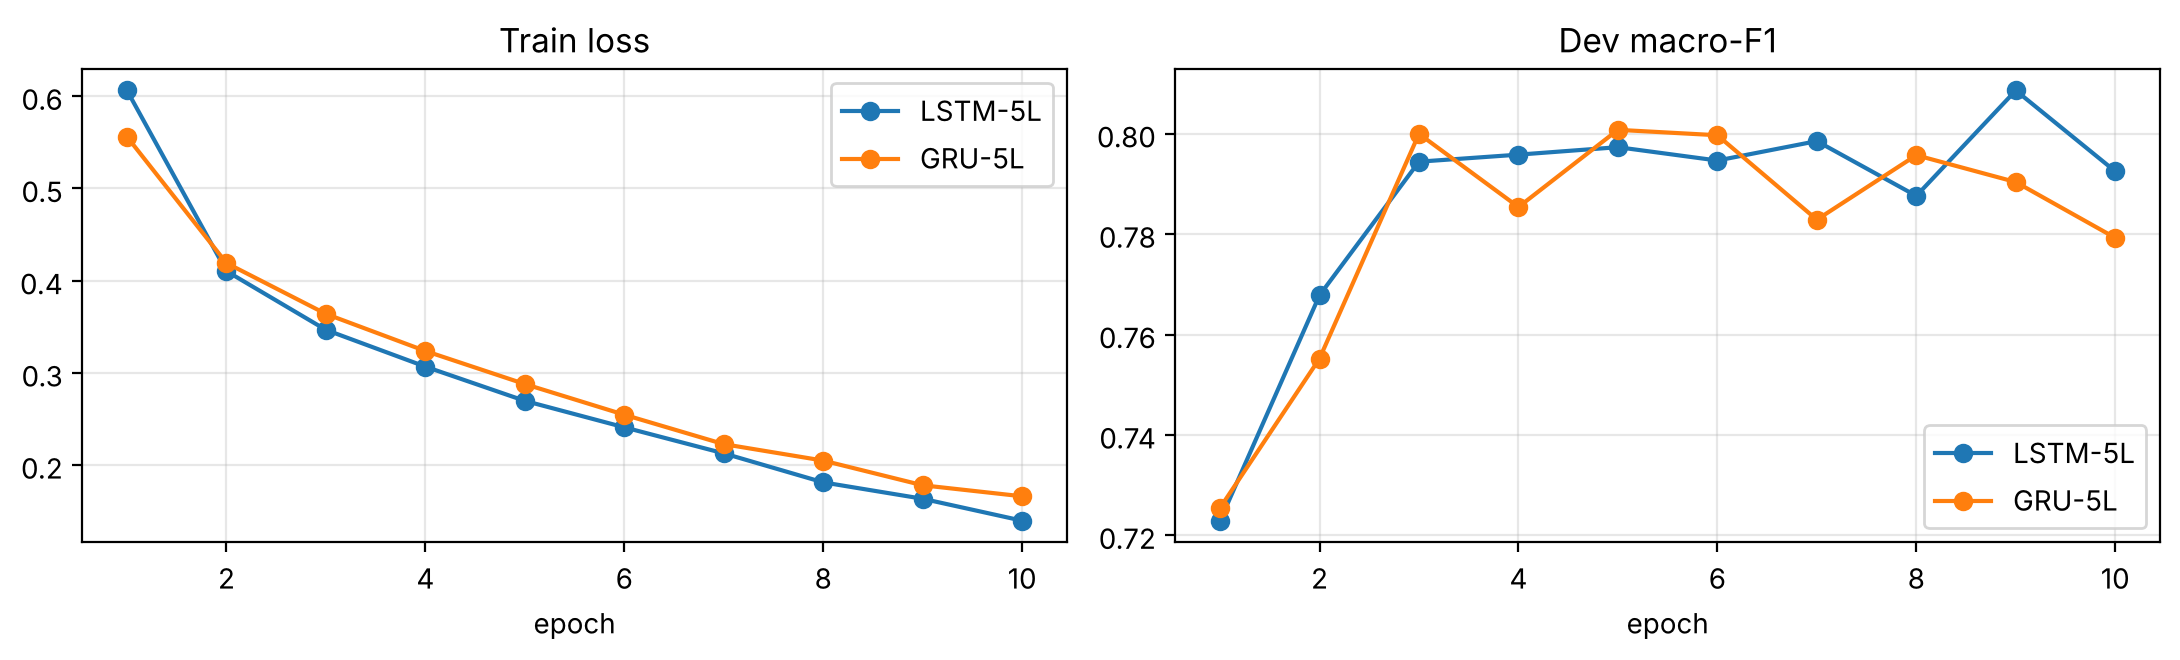

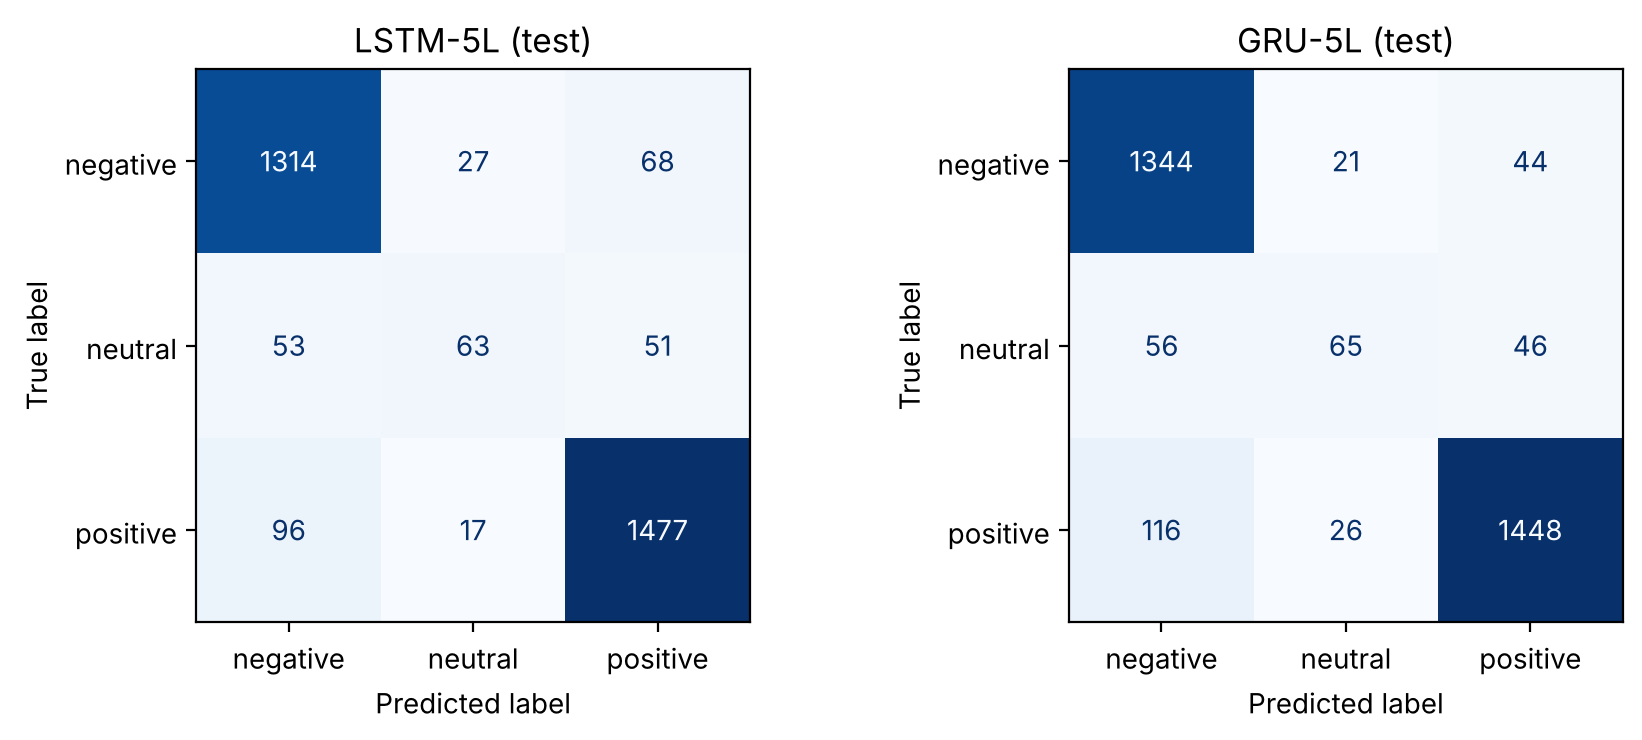

Dev: LSTM sai 123, GRU sai 119, cả hai cùng sai 94 câu


In [ ]:
plot_curves({"LSTM-5L": lstm_hist, "GRU-5L": gru_hist}, "macro-F1", OUT_DIR / "lstm_vs_gru_curves.png")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, pred) in zip(axes, [("LSTM-5L", lstm_test_pred), ("GRU-5L", gru_test_pred)]):
    ConfusionMatrixDisplay.from_predictions(cls_labels["test"], pred, display_labels=SENTIMENTS,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name} (test)")
fig.tight_layout()
plt.show()

gru_err = error_table(gru)
both = set(lstm_err.index) & set(gru_err.index)
print(f"Dev: LSTM sai {len(lstm_err)}, GRU sai {len(gru_err)}, cả hai cùng sai {len(both)} câu")

**Nhận xét:**

- **Chất lượng ngang nhau:** chênh 0.003 macro-F1 trên test, và thứ hạng đảo chiều giữa dev và test. Với một seed, không kết luận được mô hình nào tốt hơn. Hai mô hình sai chung 94 câu dev, cho thấy lỗi chủ yếu đến từ dữ liệu chứ không phải từ loại cell.
- **Chi phí:** GRU (3 cổng) ít tham số hơn khoảng 21% và nhanh hơn khoảng 11% mỗi epoch.
- **Hội tụ:** train loss giảm đều, nhưng dev F1 bão hòa từ epoch 3. GRU đạt đỉnh ở epoch 5 rồi giảm, có dấu hiệu overfit.
- **So với baseline:** cả hai hơn TF-IDF khoảng 3.5 điểm macro-F1, chủ yếu nhờ lớp neutral (0.39 lên 0.46).

## Bài 3 — Encoder BiLSTM 5 lớp cho NER

Giữ nguyên words/tags của PhoNER bản syllable. Encoder 5 lớp BiLSTM (256 mỗi chiều) → Linear(512, 21), loss `CrossEntropyLoss(ignore_index=-100)`. Dự đoán được cắt theo độ dài thật trước khi chấm bằng seqeval (strict IOB2).

In [ ]:
TAGS = sorted({t for r in phoner["train"] for t in r["tags"]})
TAG2ID = {t: i for i, t in enumerate(TAGS)}
assert len(TAGS) == 21 and all(t in TAG2ID for s in ("dev", "test") for r in phoner[s] for t in r["tags"])

ner_vocab = Vocab([r["words"] for r in phoner["train"]])
ner_gold = {s: [r["tags"] for r in phoner[s]] for s in SPLITS}
ner_data = {s: IndexedDataset([ner_vocab.encode(r["words"]) for r in phoner[s]],
                              [[TAG2ID[t] for t in r["tags"]] for r in phoner[s]]) for s in SPLITS}
ner_train_loader = make_loader(ner_data["train"], shuffle=True, seq_targets=True)
ner_eval_loader = {s: make_loader(ner_data[s], shuffle=False, seq_targets=True) for s in ("dev", "test")}

entity_types = sorted({t[2:] for t in TAGS if t != "O"})
print(f"Vocab: {len(ner_vocab)} | {len(TAGS)} nhãn BIO | {len(entity_types)} loại thực thể: {entity_types}")

Vocab: 2813 | 21 nhãn BIO | 10 loại thực thể: ['AGE', 'DATE', 'GENDER', 'JOB', 'LOCATION', 'NAME', 'ORGANIZATION', 'PATIENT_ID', 'SYMPTOM_AND_DISEASE', 'TRANSPORTATION']


In [ ]:
class BiLSTMTagger(nn.Module):
    def __init__(self, vocab_size, n_tags, cfg=CFG):
        super().__init__()
        self.encoder = RecurrentEncoder(vocab_size, "lstm", bidirectional=True, cfg=cfg)
        self.dropout = nn.Dropout(cfg.dropout)
        self.classifier = nn.Linear(self.encoder.out_dim, n_tags)

    def forward(self, ids, lengths):
        out, _, _ = self.encoder(ids, lengths)
        return self.classifier(self.dropout(out))


@torch.no_grad()
def predict_tags(model, loader):
    model.eval()
    collected = {}
    for idx, ids, lengths, _ in loader:
        best = model(ids.to(DEVICE), lengths).argmax(-1).cpu()
        for i, n, row in zip(idx.tolist(), lengths.tolist(), best):
            collected[i] = [TAGS[t] for t in row[:n].tolist()]
    return [collected[i] for i in range(len(collected))]


def entity_f1_on(split):
    return lambda model, loader: seq_f1(ner_gold[split], predict_tags(model, loader), mode="strict", scheme=IOB2, zero_division=0)


ce_token = nn.CrossEntropyLoss(ignore_index=IGNORE)
ner_loss = lambda logits, y: ce_token(logits.flatten(0, 1), y.flatten())

In [ ]:
set_seed()
tagger = BiLSTMTagger(len(ner_vocab), len(TAGS)).to(DEVICE)
print(tagger.encoder.rnn, tagger.classifier, f"\nSố tham số: {n_params(tagger):,}", sep="\n")
ner_hist, ner_best = train_with_selection(tagger, "BiLSTM-NER-5L", ner_train_loader, ner_eval_loader["dev"],
                                          ner_loss, entity_f1_on("dev"))
print(f"Checkpoint chọn: epoch {ner_best['epoch']} (dev entity-F1 {ner_best['dev_f1']:.4f})")

LSTM(300, 256, num_layers=5, batch_first=True, dropout=0.3, bidirectional=True)
Linear(in_features=512, out_features=21, bias=True)

Số tham số: 8,305,297


[BiLSTM-NER-5L] epoch  1 | train_loss 0.6975 | dev_F1 0.6297 | 101.5s  ← best


[BiLSTM-NER-5L] epoch  2 | train_loss 0.2018 | dev_F1 0.8092 | 103.5s  ← best


[BiLSTM-NER-5L] epoch  3 | train_loss 0.1251 | dev_F1 0.8721 | 104.4s  ← best


[BiLSTM-NER-5L] epoch  4 | train_loss 0.0940 | dev_F1 0.8689 | 107.4s


[BiLSTM-NER-5L] epoch  5 | train_loss 0.0747 | dev_F1 0.8784 | 103.2s  ← best


[BiLSTM-NER-5L] epoch  6 | train_loss 0.0623 | dev_F1 0.8965 | 102.4s  ← best


[BiLSTM-NER-5L] epoch  7 | train_loss 0.0500 | dev_F1 0.9015 | 103.2s  ← best


[BiLSTM-NER-5L] epoch  8 | train_loss 0.0462 | dev_F1 0.8957 | 100.5s


[BiLSTM-NER-5L] epoch  9 | train_loss 0.0411 | dev_F1 0.9078 | 101.4s  ← best


[BiLSTM-NER-5L] epoch 10 | train_loss 0.0360 | dev_F1 0.9078 | 103.1s
Checkpoint chọn: epoch 9 (dev entity-F1 0.9078)


In [ ]:
ner_test_pred = predict_tags(tagger, ner_eval_loader["test"])
kw = dict(mode="strict", scheme=IOB2, zero_division=0)
ner_test = {"precision": seq_p(ner_gold["test"], ner_test_pred, **kw),
            "recall": seq_r(ner_gold["test"], ner_test_pred, **kw),
            "f1_micro": seq_f1(ner_gold["test"], ner_test_pred, **kw)}
results["BiLSTM-NER-5L"] = dict(dev_f1=ner_best["dev_f1"], test=ner_test, params=n_params(tagger),
                                sec_per_epoch=ner_hist.sec.mean(), best_epoch=ner_best["epoch"])
print(pd.Series(ner_test).round(4).to_string())
print(f"Tham số: {n_params(tagger):,} | giây/epoch: {ner_hist.sec.mean():.1f} | best epoch: {ner_best['epoch']}\n")
print(seq_report(ner_gold["test"], ner_test_pred, digits=4, **kw))

precision    0.9002
recall       0.8919
f1_micro     0.8961
Tham số: 8,305,297 | giây/epoch: 103.1 | best epoch: 9



                     precision    recall  f1-score   support

                AGE     0.9208    0.9588    0.9394       582
               DATE     0.9686    0.9704    0.9695      1654
             GENDER     0.9565    0.9048    0.9299       462
                JOB     0.6204    0.4913    0.5484       173
           LOCATION     0.9120    0.9104    0.9112      4441
               NAME     0.6953    0.6101    0.6499       318
       ORGANIZATION     0.8517    0.7601    0.8033       771
         PATIENT_ID     0.9349    0.9666    0.9505      2005
SYMPTOM_AND_DISEASE     0.7751    0.7676    0.7713      1136
     TRANSPORTATION     0.8750    0.8705    0.8727       193

          micro avg     0.9002    0.8919    0.8961     11735
          macro avg     0.8510    0.8210    0.8346     11735
       weighted avg     0.8981    0.8919    0.8946     11735



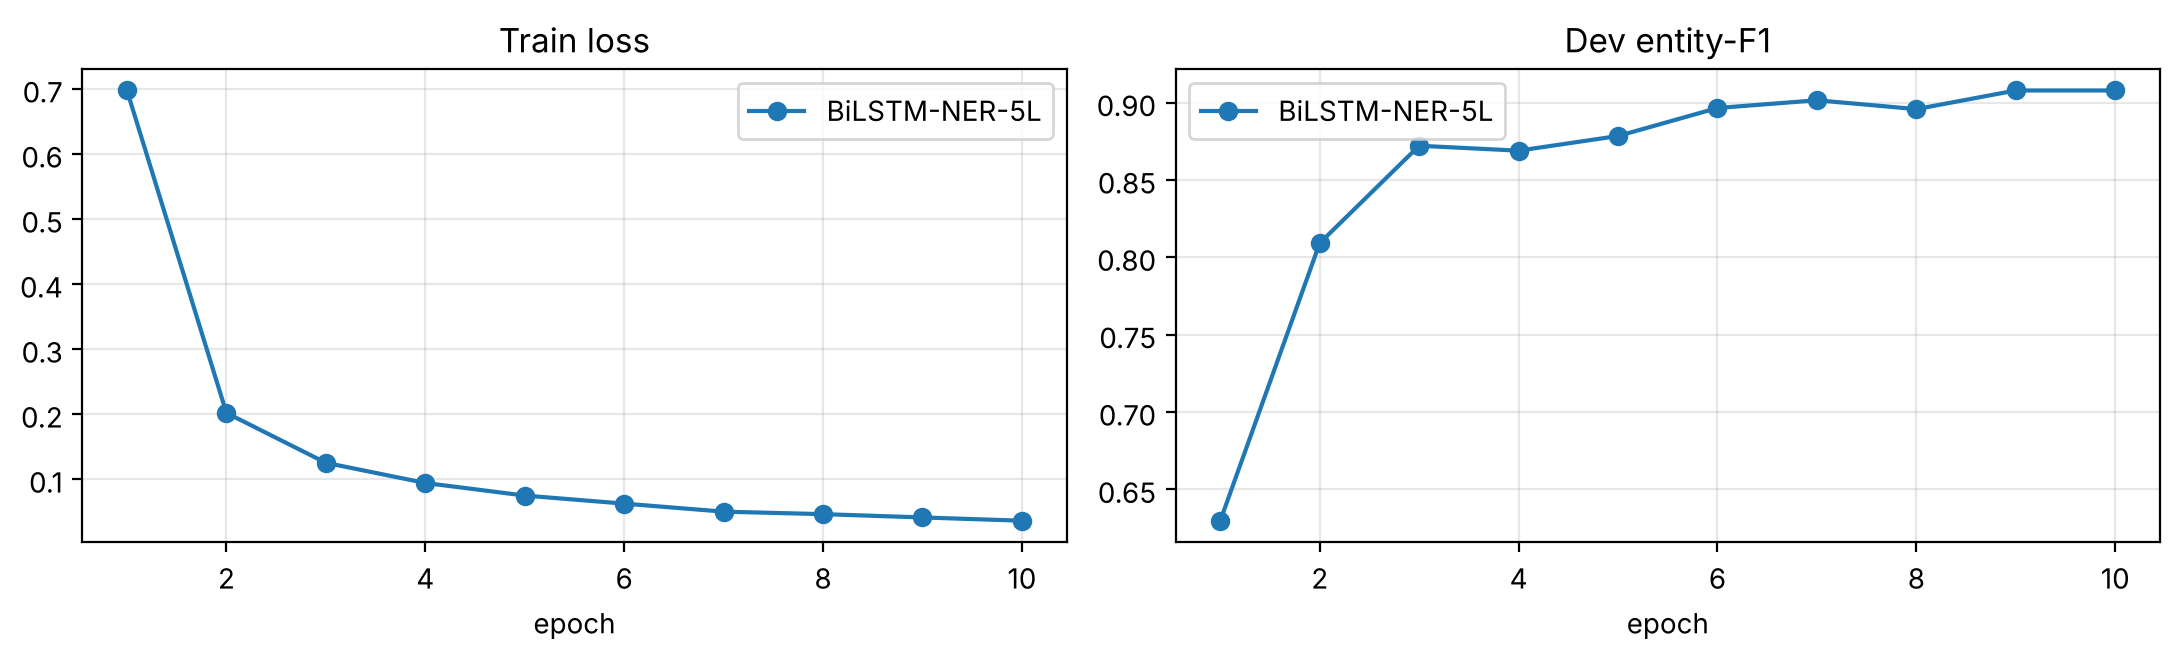

In [ ]:
plot_curves({"BiLSTM-NER-5L": ner_hist}, "entity-F1", OUT_DIR / "ner_curves.png")

### Phân tích lỗi NER trên dev

Mỗi thực thể vàng bị sai được xếp vào một nhóm: bỏ sót, sai loại, sai biên hoặc sai cả hai; thực thể dự đoán không chồng lấn với thực thể vàng nào được tính là dư thừa. Ngoài ra đếm số câu có chuỗi IOB2 không hợp lệ.

In [ ]:
def spans(tags):
    return {(s, e, t) for t, s, e in get_entities(tags)}


def ner_error_breakdown(gold_seqs, pred_seqs):
    kinds, type_swaps = Counter(), Counter()
    for g, p in zip(gold_seqs, pred_seqs):
        G, P = spans(g), spans(p)
        for s, e, t in G - P:
            overlap = [(ps, pe, pt) for ps, pe, pt in P if ps <= e and s <= pe]
            if not overlap:
                kinds["bỏ sót"] += 1
            elif any(ps == s and pe == e for ps, pe, _ in overlap):
                kinds["sai loại (đúng biên)"] += 1
                type_swaps.update(f"{t} → {pt}" for ps, pe, pt in overlap if ps == s and pe == e)
            elif any(pt == t for *_, pt in overlap):
                kinds["sai biên (đúng loại)"] += 1
            else:
                kinds["sai cả biên và loại"] += 1
        kinds["dư thừa"] += sum(not any(gs <= e and s <= ge for gs, ge, _ in G) for s, e, _ in P - G)
    return kinds, type_swaps


def invalid_iob2(tags):
    prev = "O"
    for t in tags:
        if t.startswith("I-") and prev[2:] != t[2:]:
            return True
        prev = t
    return False


ner_dev_pred = predict_tags(tagger, ner_eval_loader["dev"])
kinds, swaps = ner_error_breakdown(ner_gold["dev"], ner_dev_pred)
n_gold = sum(len(spans(g)) for g in ner_gold["dev"])
display(pd.Series(kinds, name="số lỗi").sort_values(ascending=False).to_frame()
        .assign(**{"% / thực thể vàng": lambda d: (100 * d["số lỗi"] / n_gold).round(2)}))
print("Cặp nhầm loại phổ biến nhất:", swaps.most_common(5))
print(f"Câu có chuỗi IOB2 không hợp lệ: {sum(map(invalid_iob2, ner_dev_pred))}/{len(ner_dev_pred)}")

dev_by_type = pd.DataFrame(seq_report(ner_gold["dev"], ner_dev_pred, output_dict=True, **kw)).T
dev_by_type.loc[entity_types].sort_values("f1-score")[["precision", "recall", "f1-score", "support"]].round(3)

,số lỗi,% / thực thể vàng
sai biên (đúng loại),339,4.53
dư thừa,313,4.19
bỏ sót,232,3.10
sai loại (đúng biên),108,1.44
sai cả biên và loại,31,0.41


Cặp nhầm loại phổ biến nhất: [('ORGANIZATION → LOCATION', 38), ('NAME → PATIENT_ID', 26), ('LOCATION → ORGANIZATION', 15), ('DATE → LOCATION', 4), ('NAME → TRANSPORTATION', 3)]
Câu có chuỗi IOB2 không hợp lệ: 141/2000


,precision,recall,f1-score,support
JOB,0.775,0.523,0.624,132.0
NAME,0.791,0.665,0.723,188.0
SYMPTOM_AND_DISEASE,0.777,0.816,0.796,766.0
ORGANIZATION,0.863,0.788,0.824,551.0
TRANSPORTATION,0.871,0.931,0.900,87.0
LOCATION,0.918,0.918,0.918,2737.0
GENDER,0.959,0.921,0.939,277.0
AGE,0.943,0.964,0.953,361.0
PATIENT_ID,0.957,0.975,0.966,1276.0
DATE,0.973,0.965,0.969,1103.0


In [ ]:
own_sentences = [
    "Bệnh nhân 1234 , nữ , 35 tuổi , làm nhân viên văn phòng tại quận Bình Thạnh , TP. HCM .",
    "Ngày 12/3 , Sở Y tế Đà Nẵng đã cách ly 20 người từng đến Bệnh viện Bạch Mai .",
    "Anh Nguyễn Văn An đi chuyến bay VN123 từ Hà Nội vào Cần Thơ và có triệu chứng ho , sốt .",
]
for sent in own_sentences:
    words = sent.split()
    ids = torch.tensor([ner_vocab.encode(words)], device=DEVICE)
    with torch.no_grad():
        tags = [TAGS[i] for i in tagger(ids, torch.tensor([len(words)])).argmax(-1)[0].tolist()]
    ents = [(" ".join(words[s:e + 1]), t) for t, s, e in get_entities(tags)]
    print(sent, "\n   →", ents, "\n")

Bệnh nhân 1234 , nữ , 35 tuổi , làm nhân viên văn phòng tại quận Bình Thạnh , TP. HCM . 
   → [('1234', 'PATIENT_ID'), ('nữ', 'GENDER'), ('35', 'AGE'), ('làm nhân viên văn phòng', 'JOB'), ('quận Bình Thạnh', 'LOCATION'), ('TP. HCM', 'LOCATION')] 

Ngày 12/3 , Sở Y tế Đà Nẵng đã cách ly 20 người từng đến Bệnh viện Bạch Mai . 
   → [('12/3', 'DATE'), ('Sở Y tế Đà Nẵng', 'ORGANIZATION'), ('Bệnh viện Bạch Mai', 'LOCATION')] 

Anh Nguyễn Văn An đi chuyến bay VN123 từ Hà Nội vào Cần Thơ và có triệu chứng ho , sốt . 
   → [('Anh Nguyễn Văn An', 'LOCATION'), ('VN123', 'TRANSPORTATION'), ('Hà Nội', 'LOCATION'), ('Cần Thơ', 'LOCATION'), ('ho', 'SYMPTOM_AND_DISEASE'), ('sốt', 'SYMPTOM_AND_DISEASE')] 



**Nhận xét:**

1. **Sai biên nhiều nhất** (339 thực thể): ví dụ *"làm nhân viên văn phòng"* bị gán JOB, kéo theo cả chữ "làm". JOB (F1 test 0.55) và NAME (0.65) là hai loại yếu nhất, vì biên dài và ít mẫu.
2. **Dư thừa và bỏ sót** (313 và 232): tên riêng hiếm bị đưa về `<unk>` nên mô hình chỉ dựa được vào ngữ cảnh.
3. **Sai loại:** chủ yếu ORGANIZATION ↔ LOCATION (53 trường hợp), vì "Bệnh viện …" hay "Sở Y tế …" vừa có thể là tổ chức vừa có thể là địa điểm.
4. **Chuỗi nhãn không hợp lệ:** 141/2000 câu, do softmax từng token không ràng buộc chuyển tiếp nhãn. Thêm CRF sẽ khắc phục lỗi này.

## Bảng tổng hợp kết quả

In [ ]:
summary = pd.DataFrame([{"Mô hình": n, "Dev F1 tốt nhất": r["dev_f1"],
                         "Test F1": r["test"].get("f1_macro", r["test"].get("f1_micro")),
                         "Độ đo": "entity micro-F1" if "NER" in n else "macro-F1",
                         "Best epoch": r["best_epoch"], "Tham số": r["params"],
                         "Giây/epoch": r["sec_per_epoch"]} for n, r in results.items()])
summary.to_csv(OUT_DIR / "summary.csv", index=False)
json.dump({n: {**r, "test": {k: float(v) for k, v in r["test"].items()}} for n, r in results.items()},
          open(OUT_DIR / "results.json", "w"), ensure_ascii=False, indent=2, default=float)
summary.round(4)

,Mô hình,Dev F1 tốt nhất,Test F1,Độ đo,Best epoch,Tham số,Giây/epoch
0,TF-IDF + LogReg,0.7781,0.7335,macro-F1,-,41688,0.5755
1,LSTM-5L,0.8086,0.7674,macro-F1,9,3138775,42.7518
2,GRU-5L,0.8008,0.7703,macro-F1,5,2469591,38.2509
3,BiLSTM-NER-5L,0.9078,0.8961,entity micro-F1,9,8305297,103.0584
